In [1]:
import warnings
warnings.filterwarnings("ignore")

## Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

sns.set_style("whitegrid")

## Load the Dataset

In [3]:
data = pd.read_csv("student-lifestyle-and-stress-dataset.csv")

In [4]:
data.head()

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
0,school,6.868702,1.711722,3.176942,NaN,8.0,7.0,2.0,1
1,school,8.519088,3.251084,3.880787,93.978465,6.0,4.0,3.0,1
2,college,4.498770,6.306885,2.936172,64.421253,7.0,1.0,12.0,1
3,school,8.591223,2.384922,5.222832,81.868960,2.0,7.0,7.0,0
4,college,5.329293,9.345179,7.815869,85.847982,5.0,6.0,10.0,1


In [5]:
data.tail()

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
25495,college,7.803069,7.328193,2.018277,75.435607,5.0,1.0,12.0,0
25496,school,6.734607,2.680109,3.355559,63.387386,8.0,9.0,2.0,1
25497,college,7.701671,2.631250,2.948252,79.818930,4.0,3.0,4.0,1
25498,school,5.903426,3.450424,6.823894,96.680773,2.0,6.0,6.0,0
25499,college,7.419726,6.442748,3.356066,81.452460,9.0,5.0,6.0,1


In [6]:
print("Rows :", data.shape[0])
print("Columns :", data.shape[1])

Rows : 25500
Columns : 9


In [7]:
data.columns

Index(['Student_Type', 'Sleep_Hours', 'Study_Hours', 'Social_Media_Hours',
       'Attendance', 'Exam_Pressure', 'Family_Support', 'Month',
       'Stress_Level'],
      dtype='str')

## Basic Dataset Exploration

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 25500 entries, 0 to 25499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Student_Type        24248 non-null  str    
 1   Sleep_Hours         24167 non-null  float64
 2   Study_Hours         24223 non-null  float64
 3   Social_Media_Hours  24188 non-null  float64
 4   Attendance          24195 non-null  float64
 5   Exam_Pressure       24230 non-null  float64
 6   Family_Support      24209 non-null  float64
 7   Month               24186 non-null  float64
 8   Stress_Level        25500 non-null  int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 1.9 MB


In [9]:
data.describe()

,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
count,24167.000000,24223.000000,24188.000000,24195.000000,24230.000000,24209.000000,24186.000000,25500.000000
mean,6.458948,4.696477,3.555614,81.270961,5.369748,5.798298,6.500992,0.299882
std,1.504228,2.240148,1.901528,12.052045,2.394003,2.232371,3.455308,0.458215
min,2.008586,-1.433434,0.000040,-5.000000,1.000000,1.000000,1.000000,0.000000
25%,5.438360,3.078230,2.152249,73.738894,4.000000,4.000000,3.000000,0.000000
50%,6.542566,4.538138,3.500709,81.942959,5.000000,6.000000,6.000000,0.000000
75%,7.531571,6.135670,4.864312,90.106859,7.000000,7.000000,10.000000,1.000000
max,9.997527,22.444460,9.962134,120.000000,10.000000,10.000000,12.000000,1.000000


In [10]:
data.describe(include="object")

,Student_Type
count,24248
unique,3
top,college
freq,13391


In [11]:
data.describe(include="all")

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
count,24248,24167.000000,24223.000000,24188.000000,24195.000000,24230.000000,24209.000000,24186.000000,25500.000000
unique,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,college,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,13391,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,6.458948,4.696477,3.555614,81.270961,5.369748,5.798298,6.500992,0.299882
std,NaN,1.504228,2.240148,1.901528,12.052045,2.394003,2.232371,3.455308,0.458215
min,NaN,2.008586,-1.433434,0.000040,-5.000000,1.000000,1.000000,1.000000,0.000000
25%,NaN,5.438360,3.078230,2.152249,73.738894,4.000000,4.000000,3.000000,0.000000
50%,NaN,6.542566,4.538138,3.500709,81.942959,5.000000,6.000000,6.000000,0.000000
75%,NaN,7.531571,6.135670,4.864312,90.106859,7.000000,7.000000,10.000000,1.000000


#### Check Missing Values

In [12]:
data.isnull().sum()

Student_Type          1252
Sleep_Hours           1333
Study_Hours           1277
Social_Media_Hours    1312
Attendance            1305
Exam_Pressure         1270
Family_Support        1291
Month                 1314
Stress_Level             0
dtype: int64

In [13]:
data.isnull().sum()/len(data) * 100

Student_Type          4.909804
Sleep_Hours           5.227451
Study_Hours           5.007843
Social_Media_Hours    5.145098
Attendance            5.117647
Exam_Pressure         4.980392
Family_Support        5.062745
Month                 5.152941
Stress_Level          0.000000
dtype: float64

In [14]:
missing = data.isnull().sum()

missing_percentage = (missing / len(data)) * 100

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percentage
})

missing_table.sort_values(by="Percentage", ascending=False)

,Missing Values,Percentage
Sleep_Hours,1333,5.227451
Month,1314,5.152941
Social_Media_Hours,1312,5.145098
Attendance,1305,5.117647
Family_Support,1291,5.062745
Study_Hours,1277,5.007843
Exam_Pressure,1270,4.980392
Student_Type,1252,4.909804
Stress_Level,0,0.000000


#### Duplicate Records

In [15]:
data.duplicated().sum()

np.int64(24)

In [16]:
data[data.duplicated()]

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
1126,college,5.568207,NaN,5.909244,97.456885,6.0,9.0,9.0,1
4072,college,8.148713,NaN,6.784068,85.370769,1.0,9.0,5.0,0
4790,college,4.277435,NaN,3.655623,79.375474,7.0,1.0,9.0,1
10050,school,8.478522,NaN,6.113217,65.564709,6.0,5.0,1.0,0
10182,school,8.036559,NaN,2.692154,65.579372,1.0,9.0,6.0,0
10862,school,5.172729,NaN,3.635343,72.431862,7.0,6.0,4.0,0
12383,college,8.560583,NaN,4.222640,120.000000,4.0,9.0,6.0,0
14020,college,5.474364,NaN,1.967293,72.122218,8.0,10.0,12.0,1
14272,school,8.796297,NaN,2.591195,76.161494,8.0,2.0,8.0,0
14603,working_student,4.564705,NaN,3.151107,97.622483,3.0,8.0,6.0,0


#### Check Data Types

In [17]:
data.dtypes

Student_Type              str
Sleep_Hours           float64
Study_Hours           float64
Social_Media_Hours    float64
Attendance            float64
Exam_Pressure         float64
Family_Support        float64
Month                 float64
Stress_Level            int64
dtype: object

In [18]:
data.dtypes.value_counts()

float64    7
str        1
int64      1
Name: count, dtype: int64

#### Categorical Columns

In [19]:
categorical_columns = data.select_dtypes(include=["object"]).columns

for column in categorical_columns:
    print("=" * 50)
    print("Column :", column)
    print("Unique Values :", data[column].unique())
    print("Total Unique :", data[column].nunique())

Column : Student_Type
Unique Values : <ArrowStringArray>
['school', 'college', 'working_student', nan]
Length: 4, dtype: str
Total Unique : 3


#### Numerical Columns

In [20]:
numerical_columns = data.select_dtypes(include=["int64", "float64"]).columns

print(numerical_columns)

Index(['Sleep_Hours', 'Study_Hours', 'Social_Media_Hours', 'Attendance',
       'Exam_Pressure', 'Family_Support', 'Month', 'Stress_Level'],
      dtype='str')


#### Check Invalid Values

In [21]:
for column in numerical_columns:
    print("="*50)
    print(column)
    print("Minimum :", data[column].min())
    print("Maximum :", data[column].max())

Sleep_Hours
Minimum : 2.008585834049811
Maximum : 9.997527332954435
Study_Hours
Minimum : -1.4334339503800193
Maximum : 22.44445955751421
Social_Media_Hours
Minimum : 3.99504250175875e-05
Maximum : 9.962134492424031
Attendance
Minimum : -5.0
Maximum : 120.0
Exam_Pressure
Minimum : 1.0
Maximum : 10.0
Family_Support
Minimum : 1.0
Maximum : 10.0
Month
Minimum : 1.0
Maximum : 12.0
Stress_Level
Minimum : 0
Maximum : 1


## Data Cleaning

#### Remove Duplicate Records

In [22]:
data.shape

(25500, 9)

In [23]:
print("Duplicate Rows :", data.duplicated().sum())

Duplicate Rows : 24


In [24]:
data.drop_duplicates(inplace=True)

In [25]:
print("Duplicate Rows :", data.duplicated().sum())

Duplicate Rows : 0


In [26]:
data.shape

(25476, 9)

#### Handle Missing Values

In [27]:
data.isnull().sum()

Student_Type          1251
Sleep_Hours           1333
Study_Hours           1253
Social_Media_Hours    1310
Attendance            1304
Exam_Pressure         1270
Family_Support        1290
Month                 1314
Stress_Level             0
dtype: int64

##### Fill Numerical Columns With Median

In [28]:
for column in numerical_columns:
    data[column] = data[column].fillna(data[column].median())

##### Fill Categorical Columns With Mode

In [29]:
for column in categorical_columns:
    data[column] = data[column].fillna(data[column].mode()[0])

##### Verify

In [30]:
data.isnull().sum()

Student_Type          0
Sleep_Hours           0
Study_Hours           0
Social_Media_Hours    0
Attendance            0
Exam_Pressure         0
Family_Support        0
Month                 0
Stress_Level          0
dtype: int64

In [31]:
data.shape

(25476, 9)

#### Standardize Text Columns

In [32]:
for column in categorical_columns:
    data[column] = data[column].str.strip()

In [33]:
for column in categorical_columns:
    data[column] = data[column].str.title()

#### Detect Outliers

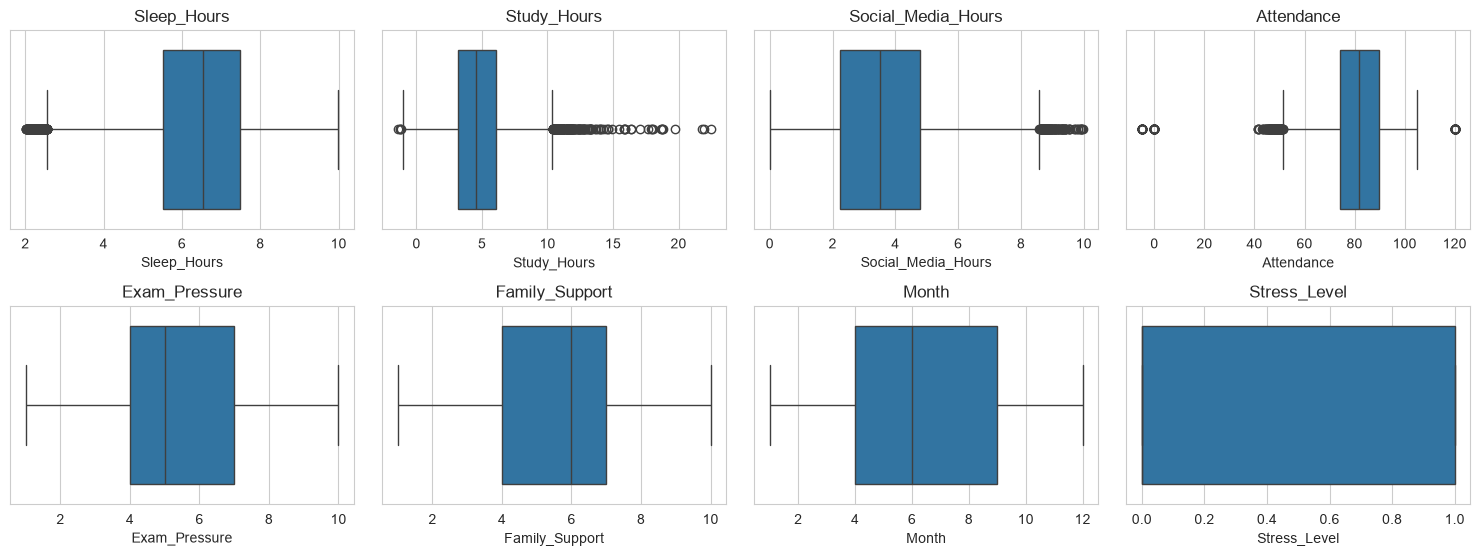

In [34]:
plt.figure(figsize=(15, 8))
for i, column in enumerate(numerical_columns, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(x=data[column])
    plt.title(column)
plt.tight_layout()
plt.show()

#### Using IQR

In [35]:
for column in numerical_columns:
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[(data[column] < lower) | (data[column] > upper)]

    print(f"{column}: {len(outliers)} outliers")

Sleep_Hours: 162 outliers
Study_Hours: 229 outliers
Social_Media_Hours: 118 outliers
Attendance: 232 outliers
Exam_Pressure: 0 outliers
Family_Support: 0 outliers
Month: 0 outliers
Stress_Level: 0 outliers


## Exploratory Data Analysis (EDA)

#### Histogram

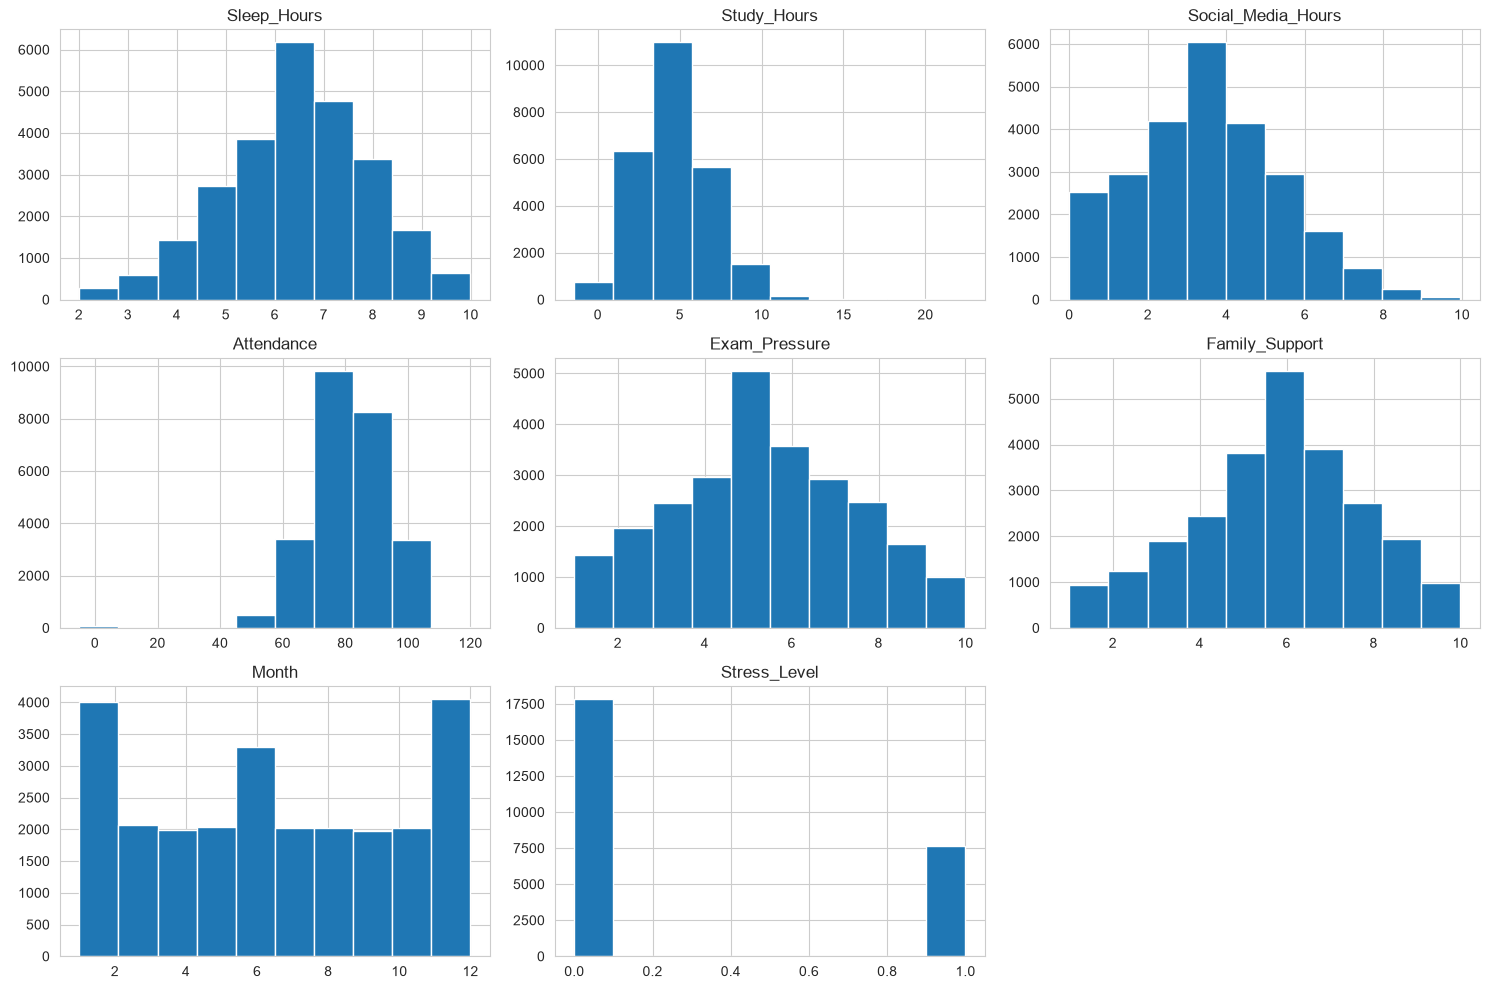

In [36]:
data.hist(figsize=(15,10))
plt.tight_layout()
plt.show()

#### Count Plot

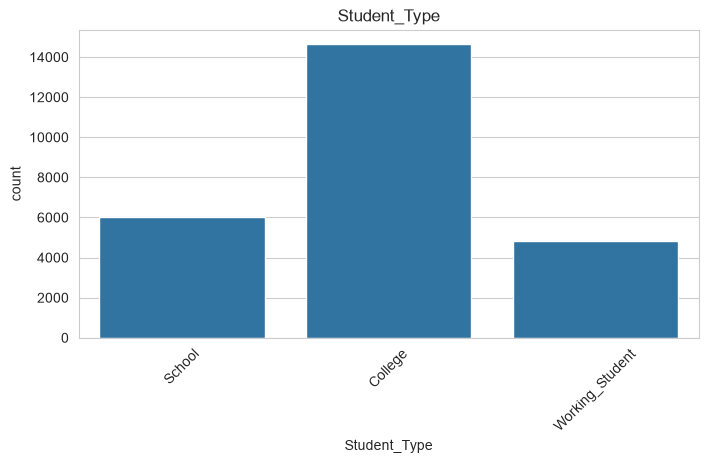

In [37]:
for column in categorical_columns:
    plt.figure(figsize=(8,4))
    sns.countplot(data=data, x=column)
    plt.xticks(rotation=45)
    plt.title(column)
    plt.show()

## Feature Engineering

#### Check Column Names

In [38]:
print(data.columns)

Index(['Student_Type', 'Sleep_Hours', 'Study_Hours', 'Social_Media_Hours',
       'Attendance', 'Exam_Pressure', 'Family_Support', 'Month',
       'Stress_Level'],
      dtype='str')


#### Remove Unnecessary Columns

Remove only those columns that have no predictive value.

In [39]:
data.drop("Month", axis=1, inplace=True)

#### Check Correlation Heatmap (Numerical Features)

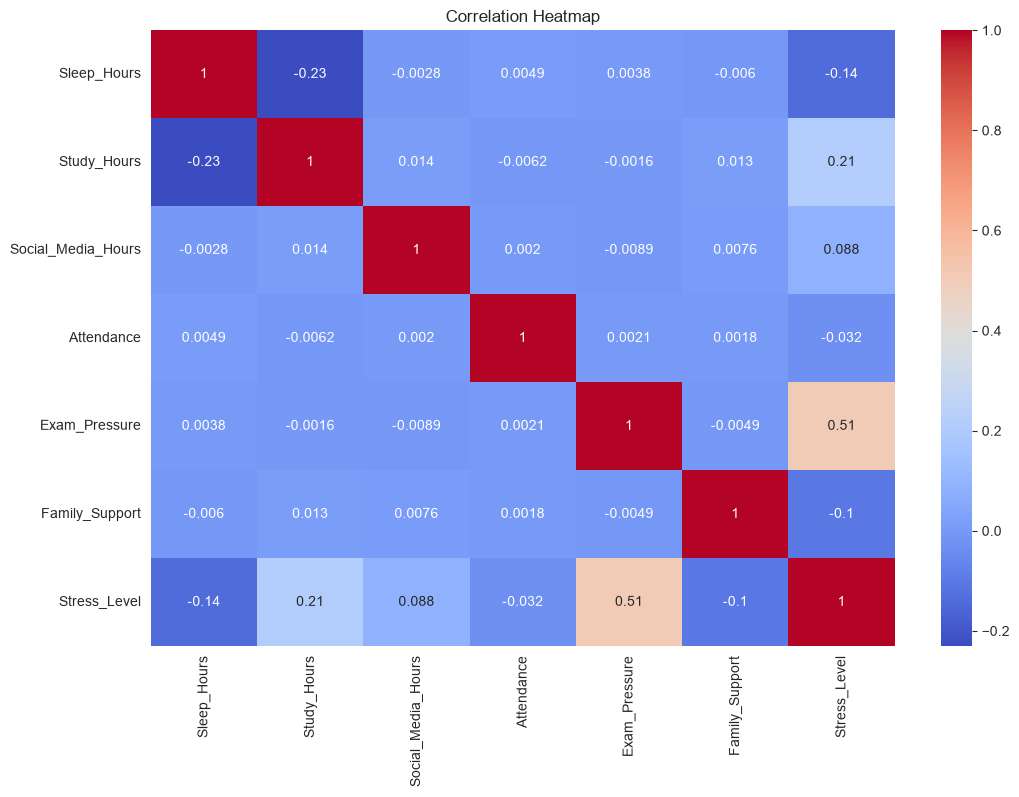

In [40]:
plt.figure(figsize=(12,8))

sns.heatmap(
    data.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

#### Separate Features & Target Variable

In [41]:
data.columns

Index(['Student_Type', 'Sleep_Hours', 'Study_Hours', 'Social_Media_Hours',
       'Attendance', 'Exam_Pressure', 'Family_Support', 'Stress_Level'],
      dtype='str')

In [42]:
X = data.drop(["Stress_Level"], axis=1)

y = data["Stress_Level"]

#### Display Shape

In [43]:
print("Feature Shape :", X.shape)
print("Target Shape :", y.shape)

Feature Shape : (25476, 7)
Target Shape : (25476,)


## Data Preprocessing

#### Check Datatypes

In [44]:
X.dtypes

Student_Type              str
Sleep_Hours           float64
Study_Hours           float64
Social_Media_Hours    float64
Attendance            float64
Exam_Pressure         float64
Family_Support        float64
dtype: object

#### Separate Numerical & Categorical Columns

In [45]:
numerical_columns = X.select_dtypes(include=["int64","float64"]).columns
categorical_columns = X.select_dtypes(include="object").columns

In [46]:
print(numerical_columns)
print(categorical_columns)

Index(['Sleep_Hours', 'Study_Hours', 'Social_Media_Hours', 'Attendance',
       'Exam_Pressure', 'Family_Support'],
      dtype='str')
Index(['Student_Type'], dtype='str')


#### Encode Categorical Variable

In [47]:
X["Student_Type"].unique()

<ArrowStringArray>
['School', 'College', 'Working_Student']
Length: 3, dtype: str

#### Categorical Column Encoding

In [48]:
X["Student_Type"] = X["Student_Type"].map({'School':0,'College':1,'Working_Student':2})

In [49]:
X.head()

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support
0,0,6.868702,1.711722,3.176942,81.941554,8.0,7.0
1,0,8.519088,3.251084,3.880787,93.978465,6.0,4.0
2,1,4.498770,6.306885,2.936172,64.421253,7.0,1.0
3,0,8.591223,2.384922,5.222832,81.868960,2.0,7.0
4,1,5.329293,9.345179,7.815869,85.847982,5.0,6.0


In [50]:
X.shape

(25476, 7)

## Train-Test Split

#### Import Library

In [51]:
from sklearn.model_selection import train_test_split

In [52]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

#### Check Shapes

In [53]:
print("Training Features :", X_train.shape)
print("Testing Features :", X_test.shape)
print("Training Target :", y_train.shape)
print("Testing Target :", y_test.shape)

Training Features : (20380, 7)
Testing Features : (5096, 7)
Training Target : (20380,)
Testing Target : (5096,)


## Feature Scaling

#### Import StandardScaler

In [54]:
from sklearn.preprocessing import StandardScaler

#### Create Scaler Object

In [55]:
scaler = StandardScaler()

#### Scale Training Data

In [56]:
X_train = scaler.fit_transform(X_train)

#### Scale Testing Data

In [57]:
X_test = scaler.transform(X_test)

#### Convert Back to DataFrame

In [58]:
X_train = pd.DataFrame(X_train,columns=X.columns)

In [59]:
X_test = pd.DataFrame(X_test,columns=X.columns)

In [60]:
X_train.head()

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support
0,-1.465229,0.478909,-1.255902,1.030010,0.325200,1.131682,-0.380131
1,0.069034,0.294439,-0.067402,0.506328,-1.402287,1.560264,1.466828
2,-1.465229,0.056968,-0.310020,2.117781,-0.689960,0.274519,0.543349
3,0.069034,-0.636523,-0.556749,-0.029219,0.095262,0.703101,-0.380131
4,0.069034,0.185215,-0.867024,0.006217,0.180564,1.560264,0.081609


In [61]:
X_test.head()

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support
0,0.069034,0.540941,0.302700,-1.479953,-0.713956,-1.011225,0.543349
1,-1.465229,1.712262,-0.861254,0.612861,0.208087,-0.154062,0.543349
2,1.603297,-0.351314,0.105498,-0.348486,-0.734340,-0.582644,-0.380131
3,-1.465229,1.632603,-1.151831,0.966235,0.855641,-1.011225,1.928568
4,1.603297,1.968383,1.596166,1.076597,0.737200,-0.154062,0.081609


#### Save Scaler

In [62]:
import joblib

joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

### Model Selection

#### Classification Algorithms

In [63]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

In [64]:
lr_model = LogisticRegression(random_state=42)
dt_model = DecisionTreeClassifier(random_state=42)
rf_model = RandomForestClassifier(random_state=42)
knn_model = KNeighborsClassifier()
svm_model = SVC(random_state=42)
gb_model = GradientBoostingClassifier(random_state=42)

## Model Training

In [65]:
lr_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)
gb_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

## Model Prediction

In [66]:
lr_pred = lr_model.predict(X_test)
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)
knn_pred = knn_model.predict(X_test)
svm_pred = svm_model.predict(X_test)
gb_pred = gb_model.predict(X_test)

## Model Evaluation

In [67]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

#### Accuracy Score

In [68]:
print("="*60)
print("Logistic Regression")
print("Accuracy :", accuracy_score(y_test, lr_pred))

print("="*60)
print("Decision Tree")
print("Accuracy :", accuracy_score(y_test, dt_pred))

print("="*60)
print("Random Forest")
print("Accuracy :", accuracy_score(y_test, rf_pred))

print("="*60)
print("KNN")
print("Accuracy :", accuracy_score(y_test, knn_pred))

print("="*60)
print("Support Vector Machine")
print("Accuracy :", accuracy_score(y_test, svm_pred))

print("="*60)
print("Gradient Boosting")
print("Accuracy :", accuracy_score(y_test, gb_pred))

Logistic Regression
Accuracy : 0.820054945054945
Decision Tree
Accuracy : 0.743916797488226
Random Forest
Accuracy : 0.8122056514913658
KNN
Accuracy : 0.7868916797488226
Support Vector Machine
Accuracy : 0.8188775510204082
Gradient Boosting
Accuracy : 0.8194662480376766


#### Confusion Matrix for All Models

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
predictions = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "KNN": knn_pred,
    "SVM": svm_pred,
    "Gradient Boosting": gb_pred
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (model, pred) in zip(axes.ravel(), predictions.items()):

    sns.heatmap(
        confusion_matrix(y_test, pred),
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Low", "High"],
        yticklabels=["Low", "High"],
        annot_kws={"size":16, "weight":"bold"},
        ax=ax
    )

    ax.set_title(model, fontsize=14, fontweight="bold")
    ax.set_xlabel("Predicted", fontsize=12)
    ax.set_ylabel("Actual", fontsize=12)

plt.tight_layout()
plt.show()

## Model Comparision

In [69]:
results = pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM",
        "Gradient Boosting"
    ],
    "Accuracy":[
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred),
        accuracy_score(y_test, gb_pred)
    ]
})
results.sort_values(by="Accuracy", ascending=False,inplace=True)
results

,Model,Accuracy
0,Logistic Regression,0.820055
5,Gradient Boosting,0.819466
4,SVM,0.818878
2,Random Forest,0.812206
3,KNN,0.786892
1,Decision Tree,0.743917


## Cross Validation

Accuracy from a single train-test split can vary depending on the random split. Cross-validation evaluates the model across multiple splits, giving a more reliable estimate of performance

In [70]:
from sklearn.model_selection import cross_val_score

In [71]:
scores1 = cross_val_score(lr_model,X_train,y_train,cv=5,scoring="accuracy")
# scores2 = cross_val_score(dt_model,X_train,y_train,cv=5,scoring="accuracy")
# scores3 = cross_val_score(rf_model,X_train,y_train,cv=5,scoring="accuracy")
# scores4 = cross_val_score(knn_model,X_train,y_train,cv=5,scoring="accuracy")
# scores5 = cross_val_score(svm_model,X_train,y_train,cv=5,scoring="accuracy")
# scores6 = cross_val_score(gb_model,X_train,y_train,cv=5,scoring="accuracy")

#### Cross Validation Scores

In [72]:
print(scores1)
# print(scores2)
# print(scores3)
# print(scores4)
# print(scores5)
# print(scores6)

[0.81452404 0.81820412 0.80299313 0.80863592 0.81943081]


#### Average Accuracy Score

In [73]:
print("Average Accuracy of Logistic :", scores1.mean())
# print("Average Accuracy of Decision Tree :", scores2.mean())
# print("Average Accuracy of Random Forest :", scores3.mean())
# print("Average Accuracy of KNN :", scores4.mean())
# print("Average Accuracy of SVM :", scores5.mean())
# print("Average Accuracy of GB :", scores6.mean())

Average Accuracy of Logistic : 0.8127576054955838


## Save the Best Model

#### Import Joblib

In [74]:
import joblib

#### Save the Model

In [75]:
joblib.dump(lr_model, "student_stress_model.pkl")

['student_stress_model.pkl']

#### Save the StandardScaler

In [77]:
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

#### Coefficients of the Logistic Regression Model

__To Know:__<br>
Which features increase the probability of High Stress (positive coefficients).<br>
Which features decrease the probability of High Stress (negative coefficients).

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr_model.coef_[0]
})

feature_importance.sort_values(by="Coefficient", key=abs, ascending=False)

## Test the Saved Model with New Data

In [78]:
import joblib
import pandas as pd

In [79]:
model = joblib.load("student_stress_model.pkl")

#### Load the StandardScaler

In [80]:
scaler = joblib.load("scaler.pkl")

In [81]:
print(X.columns)

Index(['Student_Type', 'Sleep_Hours', 'Study_Hours', 'Social_Media_Hours',
       'Attendance', 'Exam_Pressure', 'Family_Support'],
      dtype='str')


In [82]:
data.head(1)

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Stress_Level
0,School,6.868702,1.711722,3.176942,81.941554,8.0,7.0,1


In [85]:
sample = X_train.loc[[123]]
print(sample)
print("Actual :", y_train.loc[123])
print("Predicted :", lr_model.predict(sample))
print("Probability :", lr_model.predict_proba(sample))
X_train.head()

     Student_Type  Sleep_Hours  Study_Hours  Social_Media_Hours  Attendance  \
123      1.603297    -2.092619     0.382476            0.396496    0.691098   

     Exam_Pressure  Family_Support  
123      -0.154062        1.928568  
Actual : 0
Predicted : [0]
Probability : [[0.77993025 0.22006975]]


,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support
0,-1.465229,0.478909,-1.255902,1.030010,0.325200,1.131682,-0.380131
1,0.069034,0.294439,-0.067402,0.506328,-1.402287,1.560264,1.466828
2,-1.465229,0.056968,-0.310020,2.117781,-0.689960,0.274519,0.543349
3,0.069034,-0.636523,-0.556749,-0.029219,0.095262,0.703101,-0.380131
4,0.069034,0.185215,-0.867024,0.006217,0.180564,1.560264,0.081609


In [86]:
new_student = pd.DataFrame({

    "Student_Type": [-1.465229],
    "Sleep_Hours": [1.759856],
    "Study_Hours": [2.574221],
    "Social_Media_Hours": [-1.023341],
    "Attendance": [0.770523],
    "Exam_Pressure": [-1.011225],
    "Family_Support": [-0.380131]

})

In [87]:
#### Scale the New Data

In [88]:
new_student_scaled = scaler.transform(new_student)

#### Predict Stress Level

In [89]:
prediction = lr_model.predict(new_student_scaled)

In [90]:
print("Predicted Class :", prediction[0])

Predicted Class : 0


In [91]:
if prediction[0] == 1:
    print("High Stress")
else:
    print("Low Stress")

Low Stress
